# PHASE 4 - SEGFORMER (TRANSFORMER)

NOTE : Approximate Training Time for this Model using GPU : 45-50 minutes;
(around 5 minutes per epoch]

In [1]:
import os
import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset

from transformers import (
    SegformerImageProcessor,
    SegformerForSemanticSegmentation,
    TrainingArguments,
    Trainer
)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cpu


/home/ilabs/Desktop/ust-aura-ust-aura-upload./fruit_env/lib/python3.12/site-packages/torch/cuda/__init__.py:187: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [3]:
# ==== Configuration ====
# Dataset provided by UST – Infinity Labs (GPU server), manually placed on disk.
# Not included in this repository. Update this path to your own local copy
# if you have access to the dataset.
DATASET_ROOT = "/path/to/dataset"
TRAIN_DIR = f"{DATASET_ROOT}/train"
VAL_DIR = f"{DATASET_ROOT}/valid"
TEST_DIR = f"{DATASET_ROOT}/test"
SAMPLE_IMAGE_PATH = f"{DATASET_ROOT}ADD A RANDOM FRUIT IMAGE PATH"
SAMPLE_DIR = f"{DATASET_ROOT}/strawberries_sample" #CREATE A FOLDER named - strawberries_samples - and add a few test pictures there
UNSEEN_IMAGES_DIR = f"{DATASET_ROOT}/unseen_dataset" #CREATE A FOLDER NAMED unseen_dataset to implement this cell with further strawberry images

In [4]:
processor = SegformerImageProcessor(
    do_resize=True,
    size={"height": 512, "width": 512},
    do_normalize=True,
    do_rescale=True
)

In [5]:
import os
from PIL import Image
from torch.utils.data import Dataset


class FruitDataset(Dataset):
    def __init__(self, root_dir, processor):
        self.processor = processor

        self.image_dir = os.path.join(root_dir, "images")
        self.mask_dir = os.path.join(root_dir, "masks")

        self.images = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        image_path = os.path.join(self.image_dir, image_name)

        mask_name = os.path.splitext(image_name)[0] + ".png"
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path)

        encoding = self.processor(
            images=image,
            segmentation_maps=mask,
            return_tensors="pt"
        )

        pixel_values = encoding["pixel_values"].squeeze()
        labels = encoding["labels"].squeeze()

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }

In [6]:
train_dataset = FruitDataset(TRAIN_DIR, processor)
val_dataset = FruitDataset(VAL_DIR, processor)
test_dataset = FruitDataset(TEST_DIR, processor)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 428
Validation: 124
Testing: 45


In [7]:
id2label = {
    0: "background",
    1: "Anthracnose Fruit Rot",
    2: "Gray Mold",
    3: "Powdery Mildew Fruit"
}

label2id = {v: k for k, v in id2label.items()}

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=4,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

model.to(device)

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([4])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([4, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SegformerForSemanticSegmentation(
  (segformer): SegformerModel(
    (stages): ModuleList(
      (0): SegformerStage(
        (patch_embeddings): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(3, 32, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
          (layer_norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        )
        (blocks): ModuleList(
          (0): SegformerLayer(
            (layernorm_before): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
            (attention): SegformerAttention(
              (q_proj): Linear(in_features=32, out_features=32, bias=True)
              (k_proj): Linear(in_features=32, out_features=32, bias=True)
              (v_proj): Linear(in_features=32, out_features=32, bias=True)
              (o_proj): Linear(in_features=32, out_features=32, bias=True)
              (sequence_reduction): SegformerSequenceReduction(
                (sequence_reduction): Conv2d(32, 32, kernel_size=(8, 8), s

In [8]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import accuracy_score

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    logits = torch.tensor(logits)

    # Resize predictions to label size
    logits = F.interpolate(
        logits,
        size=labels.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    preds = logits.argmax(dim=1).cpu().numpy()

    accuracy = accuracy_score(
        labels.flatten(),
        preds.flatten()
    )

    return {"accuracy": accuracy}

In [9]:
training_args = TrainingArguments(
    output_dir="outputs",

    learning_rate=5e-5,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    num_train_epochs=10,

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_steps=10,

    save_total_limit=2,

    load_best_model_at_end=True,

    metric_for_best_model="eval_loss",

    greater_is_better=False,

    remove_unused_columns=False,

    report_to="none"
)

In [10]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

In [11]:
trainer.train()

/home/ilabs/Desktop/ust-aura-ust-aura-upload./fruit_env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.838162,0.738577,0.877847
2,0.503377,0.384767,0.935975
3,0.332527,0.283404,0.946350
4,0.250301,0.223391,0.951730
5,0.216679,0.193974,0.954463
6,0.185708,0.179519,0.952276
7,0.165395,0.169588,0.956385
8,0.132890,0.164310,0.956313
9,0.122751,0.157729,0.957742
10,0.143375,0.157091,0.957829


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/home/ilabs/Desktop/ust-aura-ust-aura-upload./fruit_env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/home/ilabs/Desktop/ust-aura-ust-aura-upload./fruit_env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


... (13 outputs left out)

/home/ilabs/Desktop/ust-aura-ust-aura-upload./fruit_env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['segformer.stages.0.patch_embeddings.proj.weight', 'segformer.stages.0.patch_embeddings.proj.bias', 'segformer.stages.0.patch_embeddings.layer_norm.weight', 'segformer.stages.0.patch_embeddings.layer_norm.bias', 'segformer.stages.0.blocks.0.layernorm_before.weight', 'segformer.stages.0.blocks.0.layernorm_before.bias', 'segformer.stages.0.blocks.0.attention.q_proj.weight', 'segformer.stages.0.blocks.0.attention.q_proj.bias', 'segformer.stages.0.blocks.0.attention.k_proj.weight', 'segformer.stages.0.blocks.0.attention.k_proj.bias', 'segformer.stages.0.blocks.0.attention.v_proj.weight', 'segformer.stages.0.blocks.0.attention.v_proj.bias', 'segformer.stages.0.blocks.0.attention.o_proj.weight', 'segformer.stages.0.blocks.0.attention.o_proj.bias', 'segformer.stages.0.blocks.0.attention.sequence_reduction.sequence_reduction.weight', 'segformer.stages.0.blocks.0.attention.sequence_reduction.sequence_reduction.bias', 'segfo

TrainOutput(global_step=1070, training_loss=0.3420738760556016, metrics={'train_runtime': 2771.3831, 'train_samples_per_second': 1.544, 'train_steps_per_second': 0.386, 'total_flos': 7.503003015708672e+16, 'train_loss': 0.3420738760556016, 'epoch': 10.0})

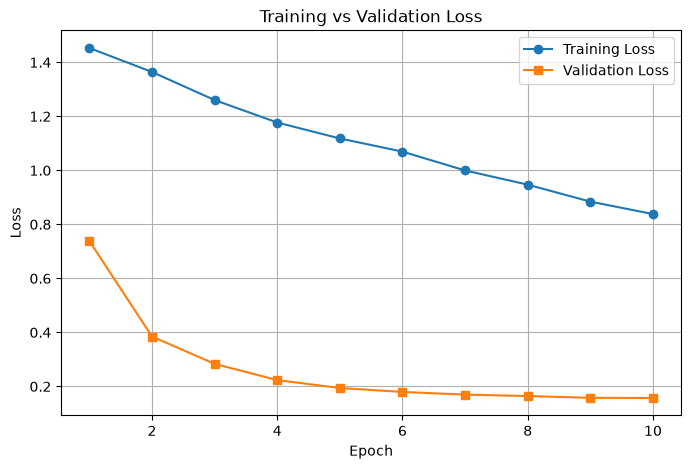

In [12]:
log_history = trainer.state.log_history

train_loss = []
val_loss = []
epochs = []

for log in log_history:

    if "loss" in log and "epoch" in log:
        train_loss.append(log["loss"])

    if "eval_loss" in log:
        val_loss.append(log["eval_loss"])
        epochs.append(log["epoch"])


import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(epochs, train_loss[:len(epochs)],
         marker='o',
         label='Training Loss')

plt.plot(epochs, val_loss,
         marker='s',
         label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

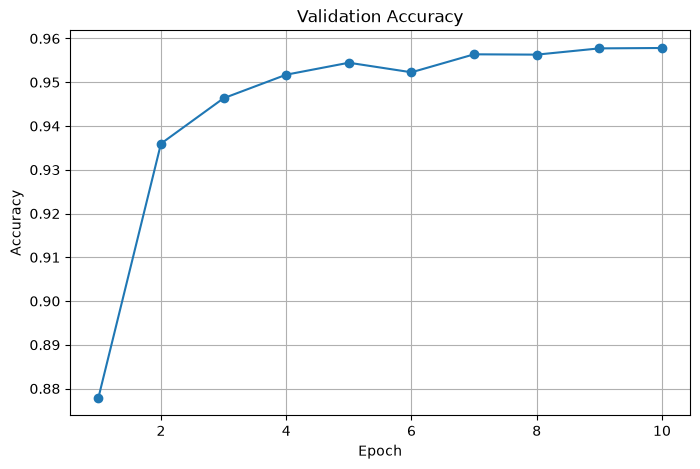

In [13]:
train_acc = []
val_acc = []

for log in trainer.state.log_history:

    if "eval_accuracy" in log:
        val_acc.append(log["eval_accuracy"])

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(val_acc)+1),
    val_acc,
    marker='o'
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.show()

In [14]:
trainer.save_model("segformer_fruit_model")
processor.save_pretrained("segformer_fruit_model")

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [15]:
import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image
import os
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    jaccard_score
)

In [16]:
model.eval()

predictions = []
ground_truths = []

with torch.no_grad():

    for sample in test_dataset:

        pixel_values = sample["pixel_values"].unsqueeze(0).to(device)

        outputs = model(pixel_values=pixel_values)

        pred = outputs.logits

        pred = torch.nn.functional.interpolate(
            pred,
            size=sample["labels"].shape,
            mode="bilinear",
            align_corners=False
        )

        pred = pred.argmax(dim=1).squeeze().cpu().numpy()

        gt = sample["labels"].numpy()

        predictions.append(pred)
        ground_truths.append(gt)

print("Inference completed!")

Inference completed!


In [17]:
all_preds = np.concatenate([p.flatten() for p in predictions])
all_labels = np.concatenate([g.flatten() for g in ground_truths])

pixel_accuracy = np.mean(all_preds == all_labels)

precision = precision_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

miou = jaccard_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

dice = (2 * precision * recall) / (precision + recall + 1e-8)

print(f"Pixel Accuracy : {pixel_accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"Mean IoU       : {miou:.4f}")
print(f"Dice Score     : {dice:.4f}")

Pixel Accuracy : 0.9592
Precision      : 0.8802
Recall         : 0.8635
F1 Score       : 0.8706
Mean IoU       : 0.7768
Dice Score     : 0.8718


In [49]:
import time
import numpy as np
import torch

model.eval()

times = []

with torch.no_grad():

    for sample in test_dataset:

        pixel_values = sample["pixel_values"].unsqueeze(0).to(device)

        # Warm-up
        _ = model(pixel_values=pixel_values)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        _ = model(pixel_values=pixel_values)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end = time.perf_counter()

        times.append(end - start)

avg_time = np.mean(times)

fps = 1 / avg_time

print(f"Average Inference Time : {avg_time*1000:.2f} ms/image")
print(f"FPS : {fps:.2f}")

Average Inference Time : 253.34 ms/image
FPS : 3.95


In [19]:
classes = [
    "Background",
    "Anthracnose",
    "Gray Mold",
    "Powdery Mildew"
]

for i, name in enumerate(classes):

    gt = (all_labels == i).astype(int)
    pr = (all_preds == i).astype(int)

    iou = jaccard_score(gt, pr, zero_division=0)

    print(f"{name:20s}: {iou:.4f}")

Background          : 0.9550
Anthracnose         : 0.6987
Gray Mold           : 0.6933
Powdery Mildew      : 0.7601


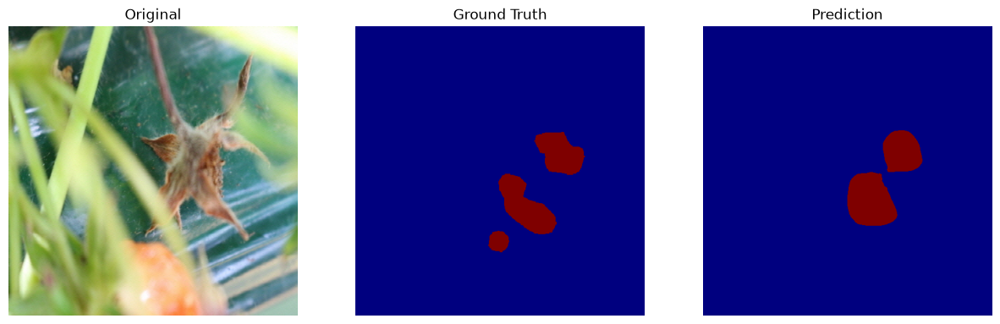

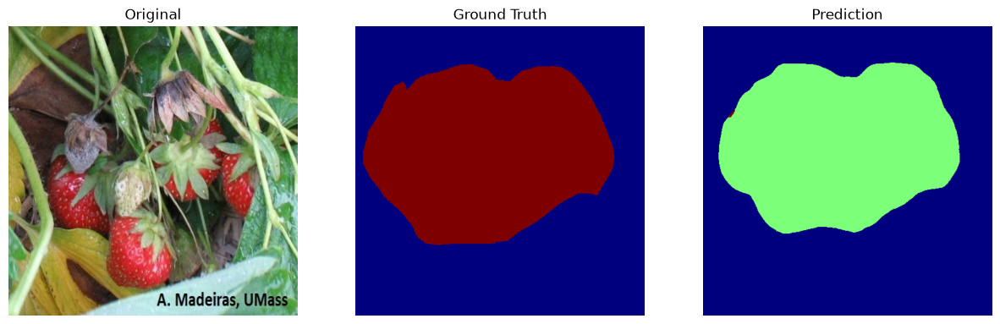

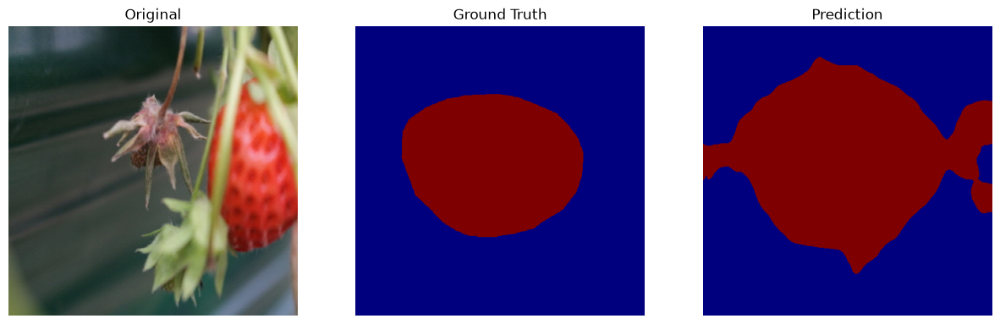

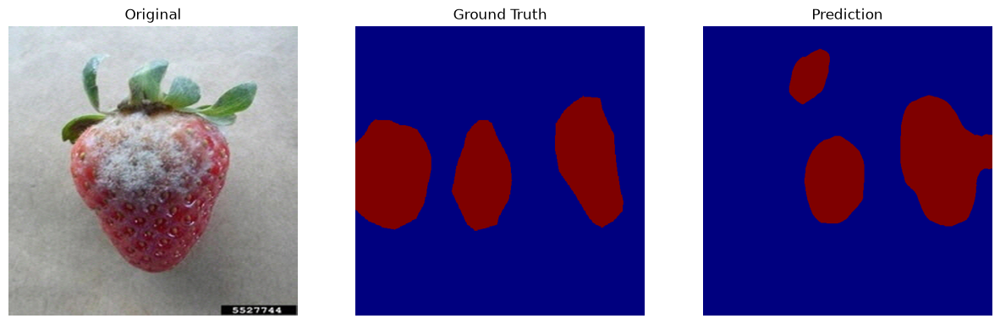

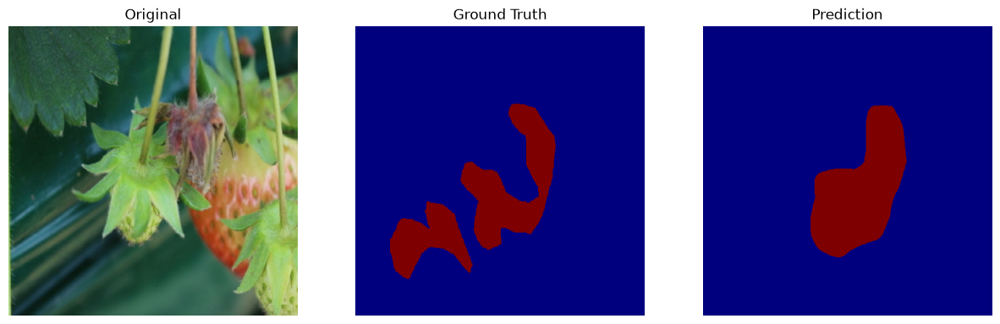

In [20]:
num_images = 5

for i in range(num_images):

    image = np.array(
        Image.open(
            os.path.join(
                TEST_DIR,
                "images",
                os.listdir(os.path.join(TEST_DIR, "images"))[i]
            )
        )
    )

    gt = ground_truths[i]
    pred = predictions[i]

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(gt, cmap="jet")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(pred, cmap="jet")
    plt.title("Prediction")
    plt.axis("off")

    plt.show()

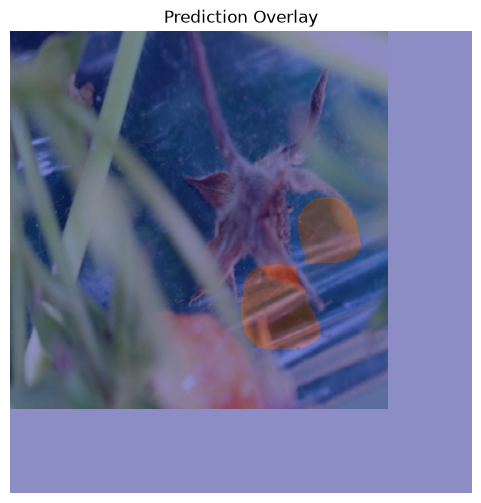

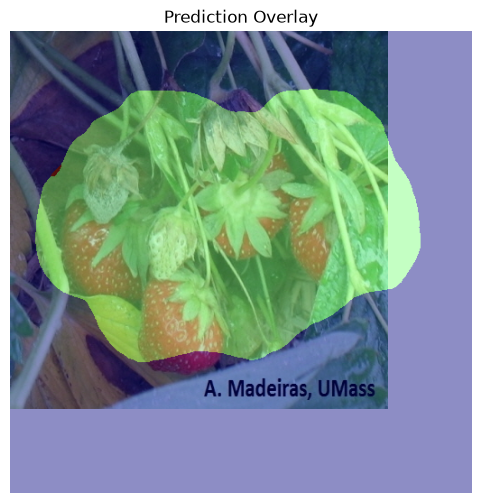

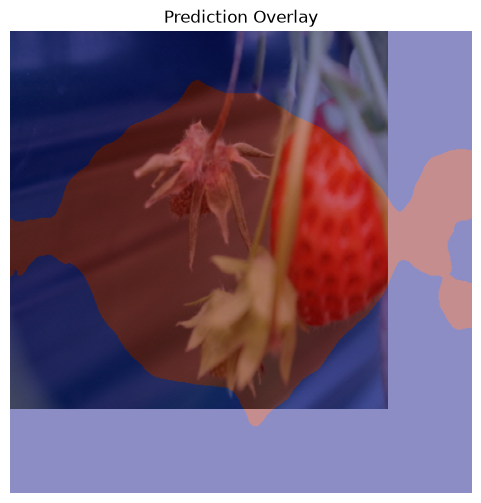

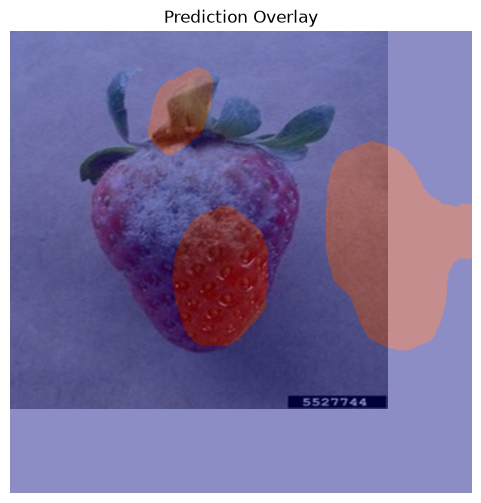

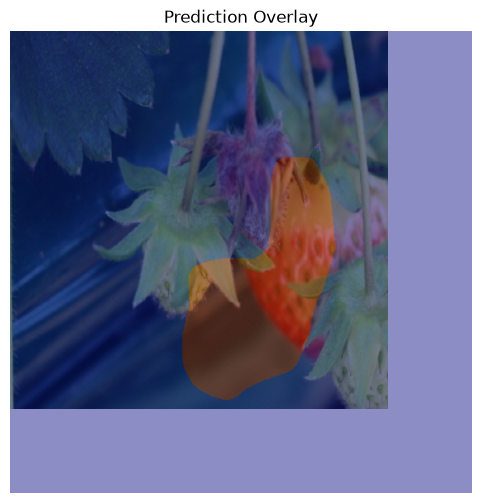

In [21]:
num_images = 5

for i in range(num_images):

    image = np.array(
        Image.open(
            os.path.join(
                TEST_DIR,
                "images",
                os.listdir(os.path.join(TEST_DIR, "images"))[i]
            )
        )
    )

    pred = predictions[i]

    plt.figure(figsize=(6,6))

    plt.imshow(image)
    plt.imshow(pred, alpha=0.45, cmap="jet")

    plt.title("Prediction Overlay")
    plt.axis("off")

    plt.show()

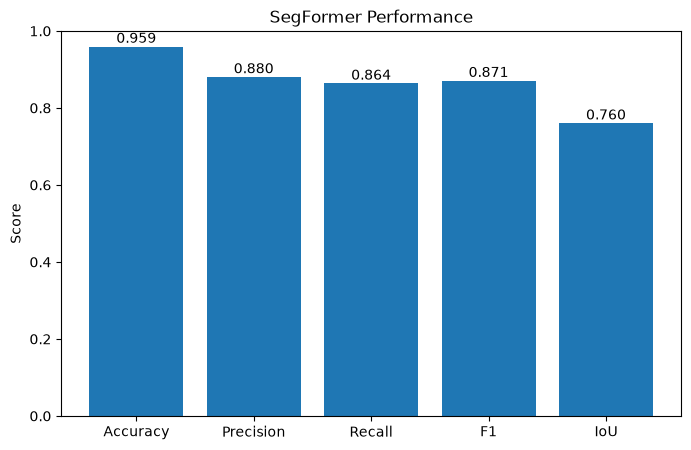

In [22]:
metrics = {
    "Accuracy": pixel_accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "IoU": iou
}

plt.figure(figsize=(8,5))

plt.bar(metrics.keys(), metrics.values())

plt.ylim(0,1)

plt.ylabel("Score")
plt.title("SegFormer Performance")

for i,v in enumerate(metrics.values()):
    plt.text(i,v+0.01,f"{v:.3f}",ha='center')

plt.show()

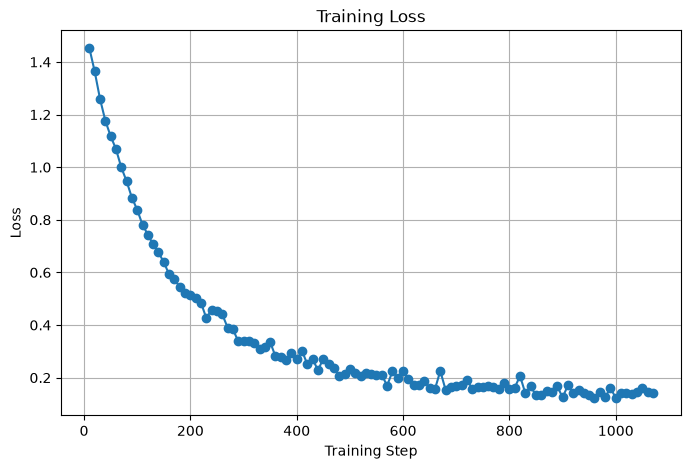

In [23]:
losses = []
steps = []

for log in trainer.state.log_history:

    if "loss" in log:

        losses.append(log["loss"])
        steps.append(log["step"])

plt.figure(figsize=(8,5))

plt.plot(steps, losses, marker='o')

plt.xlabel("Training Step")
plt.ylabel("Loss")

plt.title("Training Loss")

plt.grid(True)

plt.show()

<Figure size 800x500 with 0 Axes>

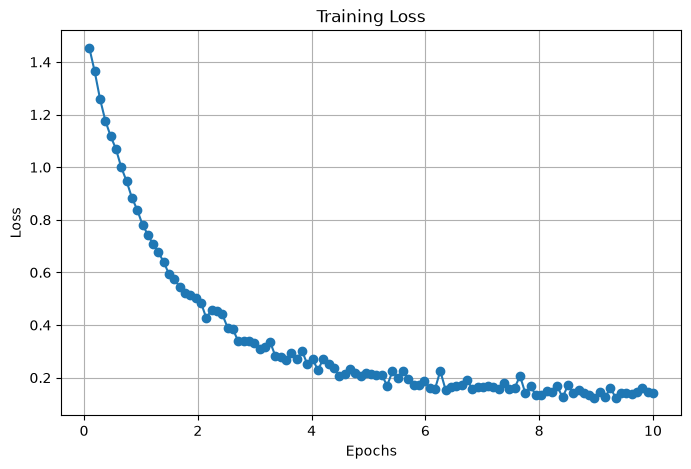

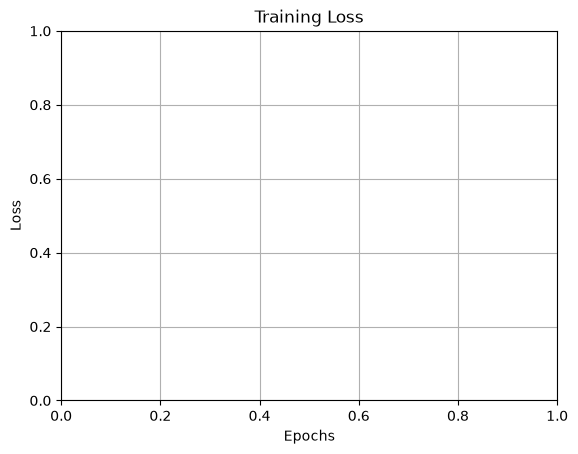

In [24]:
losses = []
epochs = []

for log in trainer.state.log_history:

    if "loss" in log:

        losses.append(log["loss"])
        steps.append(log["epoch"])

plt.figure(figsize=(8,5))

losses = []
epochs = []

for log in trainer.state.log_history:
    if "loss" in log:
        losses.append(log["loss"])
        epochs.append(log["epoch"])

plt.figure(figsize=(8, 5))
plt.plot(epochs, losses, marker='o')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("Training Loss")

plt.grid(True)

plt.show()

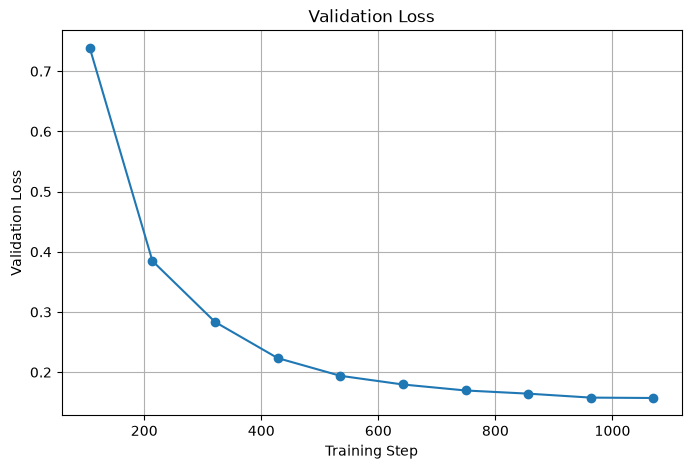

In [25]:
eval_losses = []
eval_steps = []

for log in trainer.state.log_history:

    if "eval_loss" in log:

        eval_losses.append(log["eval_loss"])
        eval_steps.append(log["step"])

if len(eval_losses) > 0:

    plt.figure(figsize=(8,5))

    plt.plot(eval_steps, eval_losses, marker='o')

    plt.xlabel("Training Step")
    plt.ylabel("Validation Loss")

    plt.title("Validation Loss")

    plt.grid(True)

    plt.show()

else:
    print("No validation loss logged.")

<Figure size 800x500 with 0 Axes>

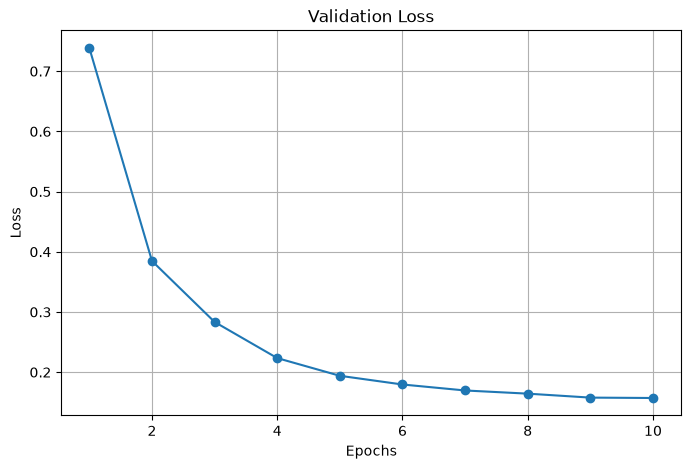

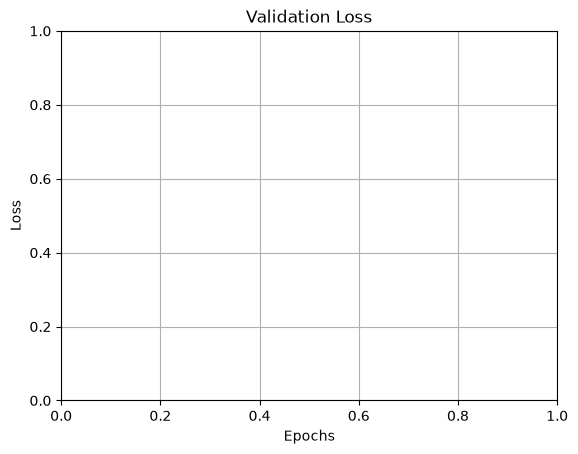

In [26]:
eval_losses = []
eval_epochs = []

for log in trainer.state.log_history:

    if "eval_loss" in log:

        eval_losses.append(log["eval_loss"])
        eval_steps.append(log["epoch"])

if len(eval_losses) > 0:

    plt.figure(figsize=(8,5))

    eval_losses = []
    eval_epochs = []

    for log in trainer.state.log_history:
        if "eval_loss" in log:
            eval_losses.append(log["eval_loss"])
            eval_epochs.append(log["epoch"])

    if len(eval_losses) > 0:
        plt.figure(figsize=(8, 5))

        plt.plot(eval_epochs, eval_losses, marker='o')

        plt.xlabel("Epochs")
        plt.ylabel("Loss")

        plt.title("Validation Loss")

        plt.grid(True)

        plt.show()

    else:
        print("No validation loss logged.")

    plt.xlabel("Epochs")
    plt.ylabel("Loss")

    plt.title("Validation Loss")

    plt.grid(True)

    plt.show()

else:
    print("No validation loss logged.")

In [27]:
import numpy as np

In [28]:
import matplotlib.pyplot as plt

In [29]:
import torch

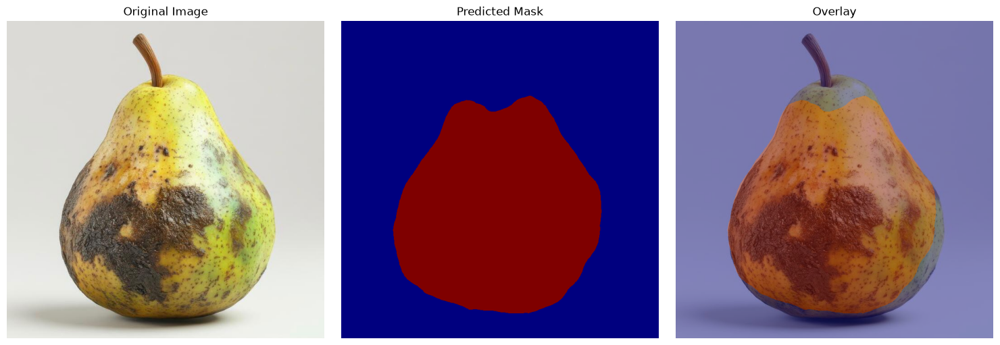

In [30]:
#JUST FOR CHECKING WHETHER THIS MODEL WORKS FOR OTHER FRUIT AS WELL APART FROM STRAWBERRIES
#******************************************************************************************
from PIL import Image

image_path = SAMPLE_IMAGE_PATH

image = Image.open(SAMPLE_IMAGE_PATH).convert("RGB")

model.eval()

# Load image
image = Image.open(image_path).convert("RGB")

# Preprocess
inputs = processor(images=image, return_tensors="pt")
inputs = {k: v.to(device) for k, v in inputs.items()}

# Prediction
with torch.no_grad():
    outputs = model(**inputs)

# Upsample prediction back to original image size
logits = torch.nn.functional.interpolate(
    outputs.logits,
    size=image.size[::-1],   # (height, width)
    mode="bilinear",
    align_corners=False
)

prediction = logits.argmax(dim=1).squeeze().cpu().numpy()

# Display
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(prediction, cmap="jet")
plt.title("Predicted Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(image)
plt.imshow(prediction, cmap="jet", alpha=0.45)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
import os
import torch
import numpy as np
from PIL import Image

#CREATE A FOLDER named strawberries_samples and add a few test pictures there

sample_images = sorted([
    f for f in os.listdir(SAMPLE_DIR)
    if f.lower().endswith((".jpg",".jpeg",".png"))
])

results = []

model.eval()

for img_name in sample_images:

    image_path = os.path.join(SAMPLE_DIR, img_name)

    image = Image.open(image_path).convert("RGB")

    inputs = processor(images=image, return_tensors="pt")
    inputs = {k:v.to(device) for k,v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    logits = torch.nn.functional.interpolate(
        outputs.logits,
        size=image.size[::-1],
        mode="bilinear",
        align_corners=False
    )

    prediction = logits.argmax(dim=1).squeeze().cpu().numpy()

    results.append({
        "name": img_name,
        "image": image,
        "prediction": prediction
    })

print(f"{len(results)} images processed successfully.")

9 images processed successfully.


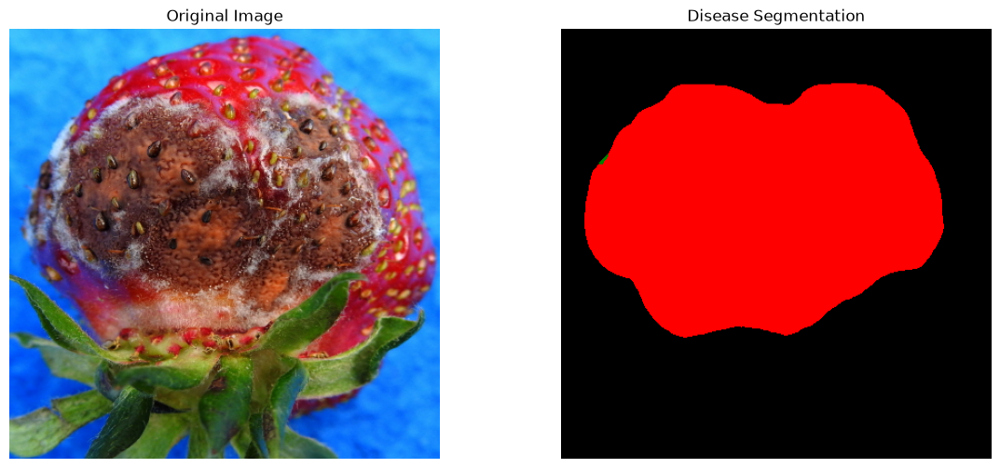

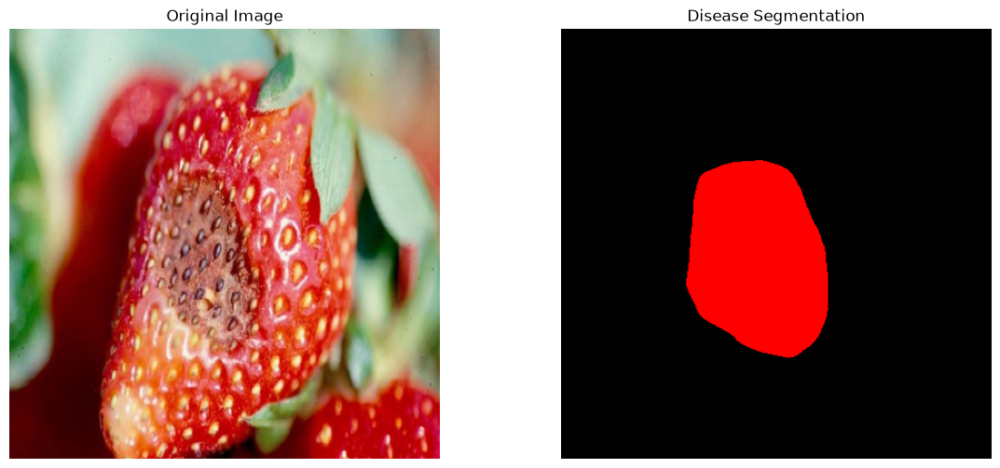

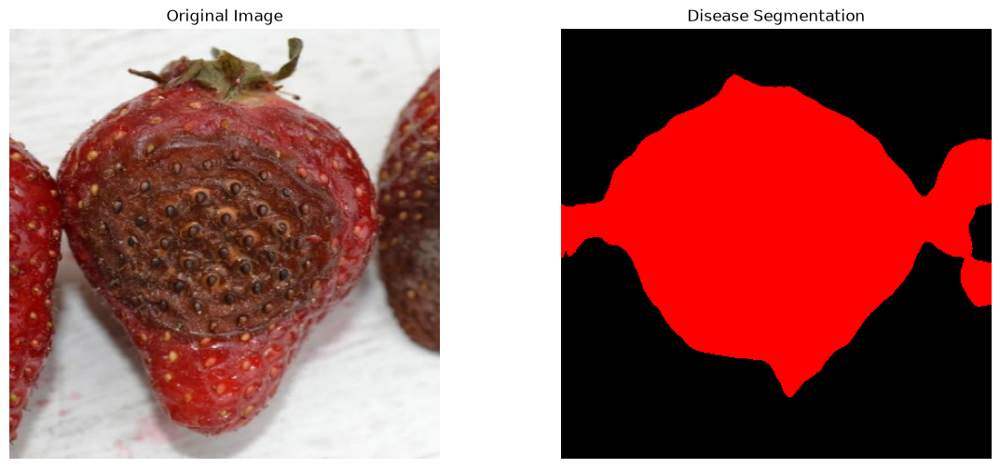

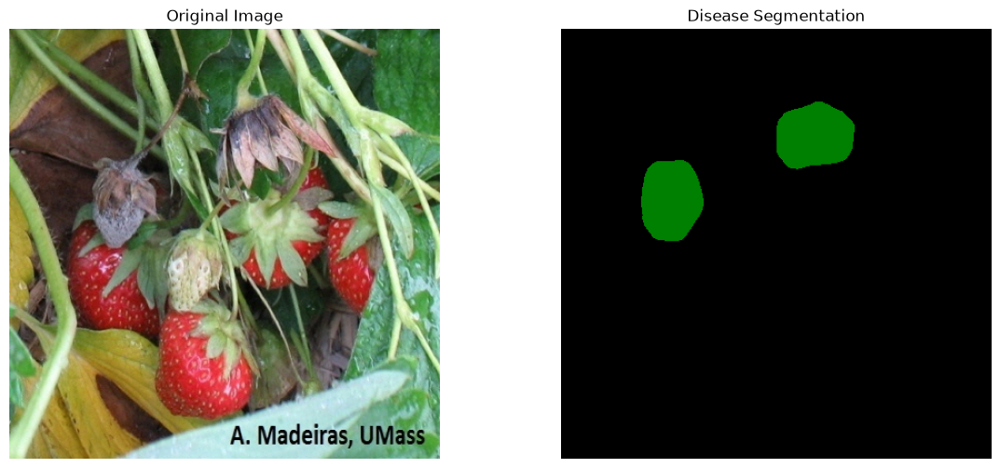

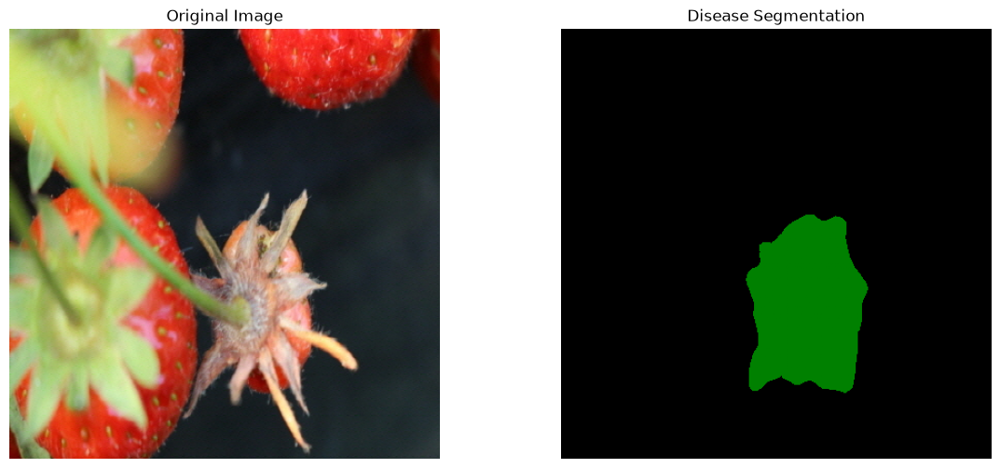

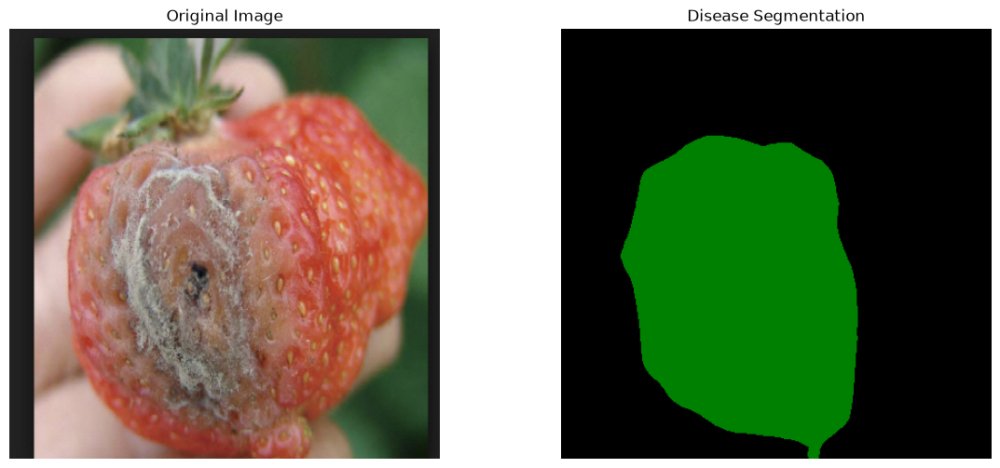

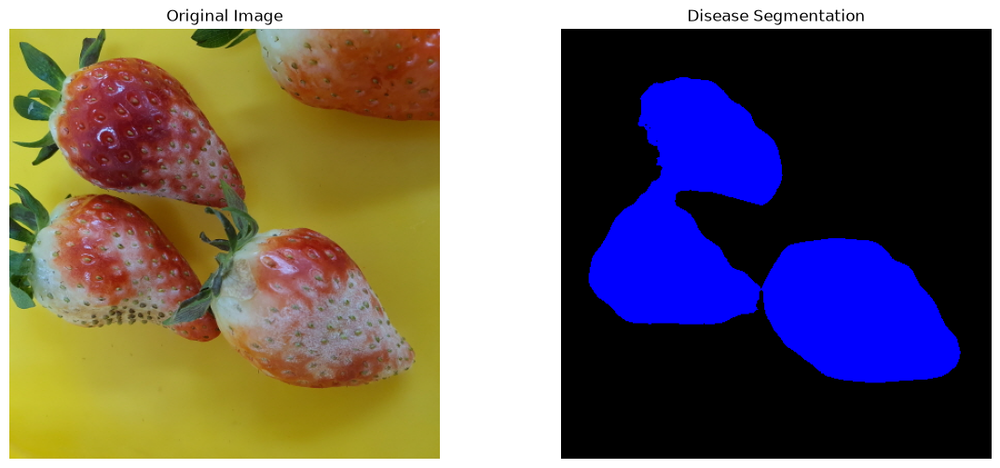

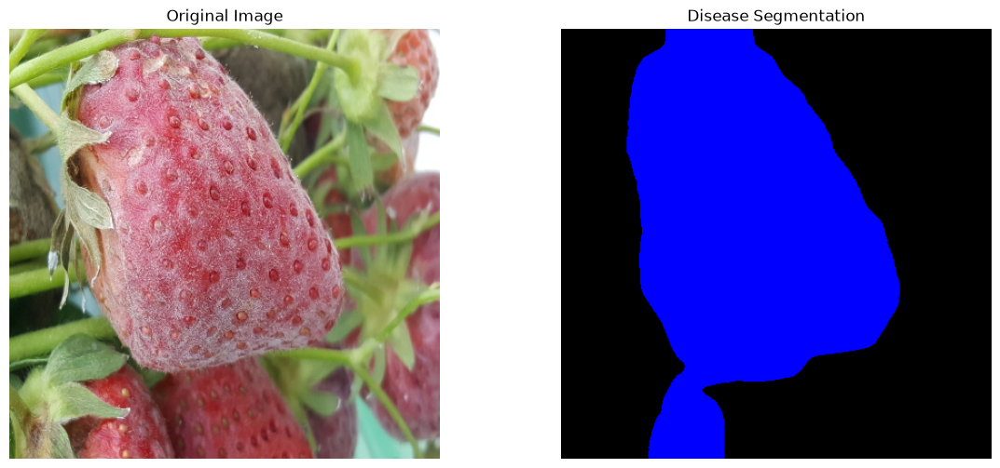

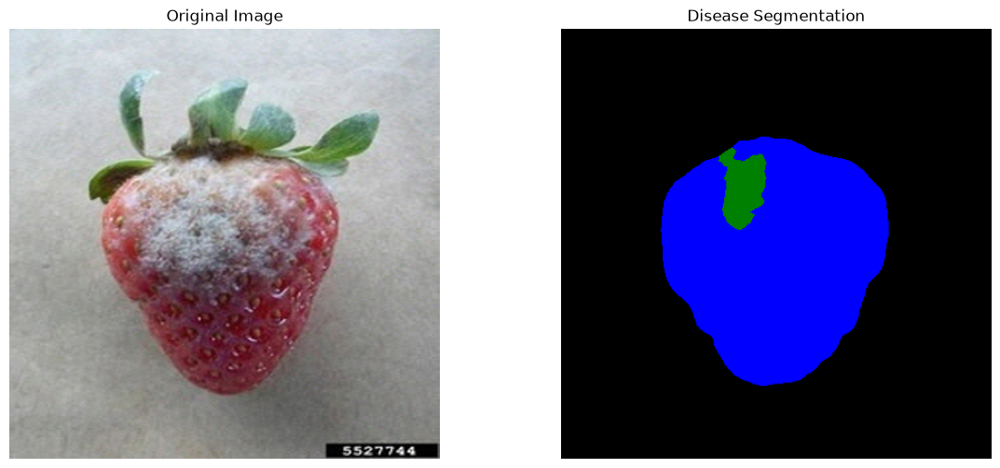

In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

colors = ListedColormap([
    "black",      # Background
    "red",        # Anthracnose
    "green",      # Gray Mold
    "blue"        # Powdery Mildew
])

for sample in results:

    plt.figure(figsize=(14,6))

    plt.subplot(1,2,1)
    plt.imshow(sample["image"])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(sample["prediction"], cmap=colors, vmin=0, vmax=3)
    plt.title("Disease Segmentation")
    plt.axis("off")

    plt.show()

In [33]:
for sample in results:

    pred = sample["prediction"]

    total_pixels = pred.size

    defect_pixels = np.sum(pred > 0)

    defect_percentage = defect_pixels / total_pixels * 100

    sample["defect_percentage"] = defect_percentage

    print(f"{sample['name']}")
    print(f"Defect Area : {defect_percentage:.2f}%")
    print("-"*40)

anthracnose 1.jpg
Defect Area : 37.99%
----------------------------------------
anthracnose_2.jpg
Defect Area : 11.92%
----------------------------------------
anthracnose_fruit_rot17_jpg.rf.LmbEvcopE5muOaHJb7S7.jpg
Defect Area : 40.60%
----------------------------------------
gray_mold132_jpg.rf.T0KQLlghgVG9IpJ3jToY.jpg
Defect Area : 4.46%
----------------------------------------
gray_mold456_jpg.rf.1J9NlEsFuYywQ0R2YaS9.jpg
Defect Area : 8.92%
----------------------------------------
gray_mold58_jpg.rf.YUXIbhIK5swYZTs7zvIP.jpg
Defect Area : 31.48%
----------------------------------------
powdery_mildew_fruit42_jpg.rf.6Pe3YMDqoyQNOjQEWCPi.jpg
Defect Area : 26.45%
----------------------------------------
powdery_mildew_fruit50_jpg.rf.CvKDM7TtHSRBaxGaxlMN.jpg
Defect Area : 40.39%
----------------------------------------
powdery_mildew_fruit98_jpg.rf.yIameWNW3CyKNoULoeqA.jpg
Defect Area : 22.48%
----------------------------------------


In [34]:
for sample in results:

    pred = sample["prediction"]

    classes = np.unique(pred)

    detected = []

    for c in classes:

        if c != 0:
            detected.append(id2label[c])

    sample["diseases"] = detected

    print(sample["name"])

    if len(detected)==0:
        print("Disease : Healthy Fruit")
    else:
        print("Diseases Detected:")

        for disease in detected:
            print("-",disease)

    print("-"*40)

anthracnose 1.jpg
Diseases Detected:
- Anthracnose Fruit Rot
- Gray Mold
----------------------------------------
anthracnose_2.jpg
Diseases Detected:
- Anthracnose Fruit Rot
----------------------------------------
anthracnose_fruit_rot17_jpg.rf.LmbEvcopE5muOaHJb7S7.jpg
Diseases Detected:
- Anthracnose Fruit Rot
----------------------------------------
gray_mold132_jpg.rf.T0KQLlghgVG9IpJ3jToY.jpg
Diseases Detected:
- Gray Mold
----------------------------------------
gray_mold456_jpg.rf.1J9NlEsFuYywQ0R2YaS9.jpg
Diseases Detected:
- Gray Mold
----------------------------------------
gray_mold58_jpg.rf.YUXIbhIK5swYZTs7zvIP.jpg
Diseases Detected:
- Gray Mold
----------------------------------------
powdery_mildew_fruit42_jpg.rf.6Pe3YMDqoyQNOjQEWCPi.jpg
Diseases Detected:
- Powdery Mildew Fruit
----------------------------------------
powdery_mildew_fruit50_jpg.rf.CvKDM7TtHSRBaxGaxlMN.jpg
Diseases Detected:
- Powdery Mildew Fruit
----------------------------------------
powdery_mildew_fru

In [35]:
for sample in results:

    percentage = sample["defect_percentage"]

    if percentage < 5:
        grade = "Healthy"

    elif percentage < 20:
        grade = "Moderately Defective"

    else:
        grade = "Highly Defective"

    print("="*60)

    print("Image :",sample["name"])

    print(f"Defect Percentage : {percentage:.2f}%")

    if len(sample["diseases"])==0:
        print("Disease : Healthy")
    else:
        print("Detected Disease(s):")

        for disease in sample["diseases"]:
            print("•",disease)

    print("Quality Grade :",grade)

    print("="*60)

Image : anthracnose 1.jpg
Defect Percentage : 37.99%
Detected Disease(s):
• Anthracnose Fruit Rot
• Gray Mold
Quality Grade : Highly Defective
Image : anthracnose_2.jpg
Defect Percentage : 11.92%
Detected Disease(s):
• Anthracnose Fruit Rot
Quality Grade : Moderately Defective
Image : anthracnose_fruit_rot17_jpg.rf.LmbEvcopE5muOaHJb7S7.jpg
Defect Percentage : 40.60%
Detected Disease(s):
• Anthracnose Fruit Rot
Quality Grade : Highly Defective
Image : gray_mold132_jpg.rf.T0KQLlghgVG9IpJ3jToY.jpg
Defect Percentage : 4.46%
Detected Disease(s):
• Gray Mold
Quality Grade : Healthy
Image : gray_mold456_jpg.rf.1J9NlEsFuYywQ0R2YaS9.jpg
Defect Percentage : 8.92%
Detected Disease(s):
• Gray Mold
Quality Grade : Moderately Defective
Image : gray_mold58_jpg.rf.YUXIbhIK5swYZTs7zvIP.jpg
Defect Percentage : 31.48%
Detected Disease(s):
• Gray Mold
Quality Grade : Highly Defective
Image : powdery_mildew_fruit42_jpg.rf.6Pe3YMDqoyQNOjQEWCPi.jpg
Defect Percentage : 26.45%
Detected Disease(s):
• Powdery Mi

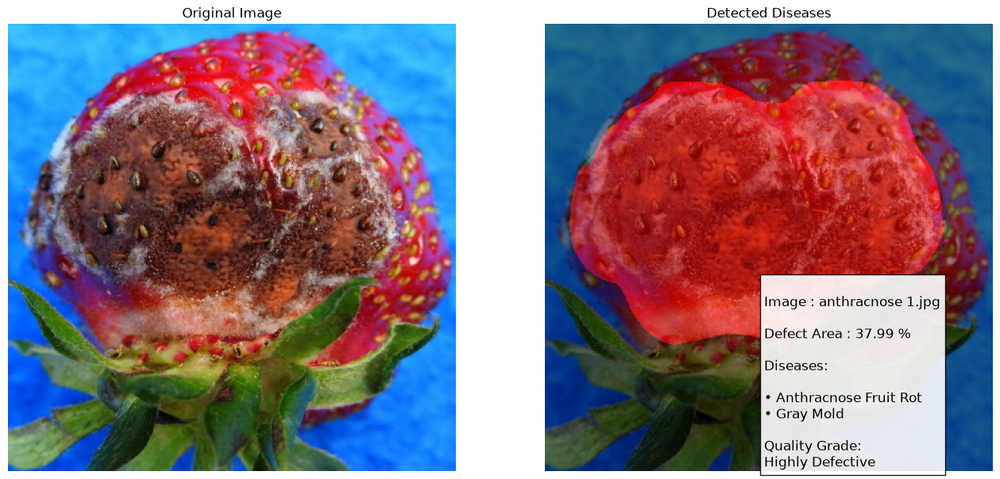

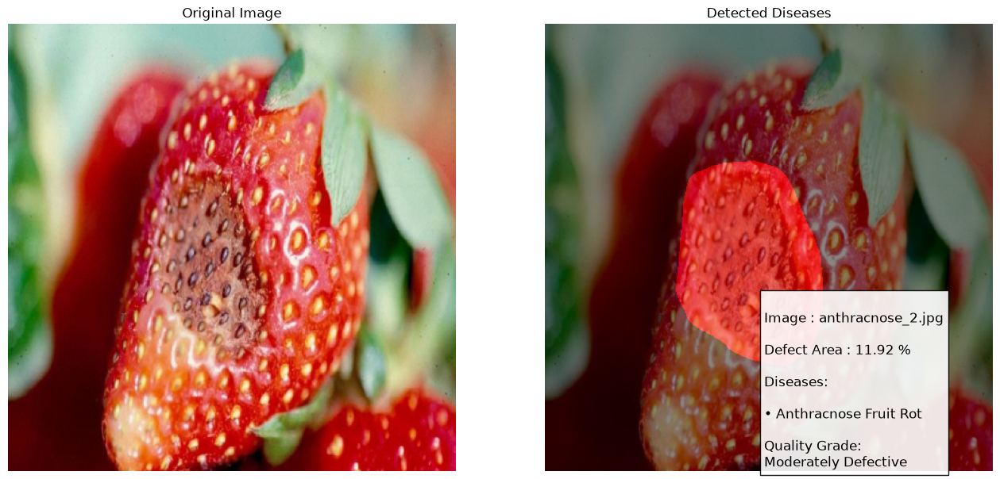

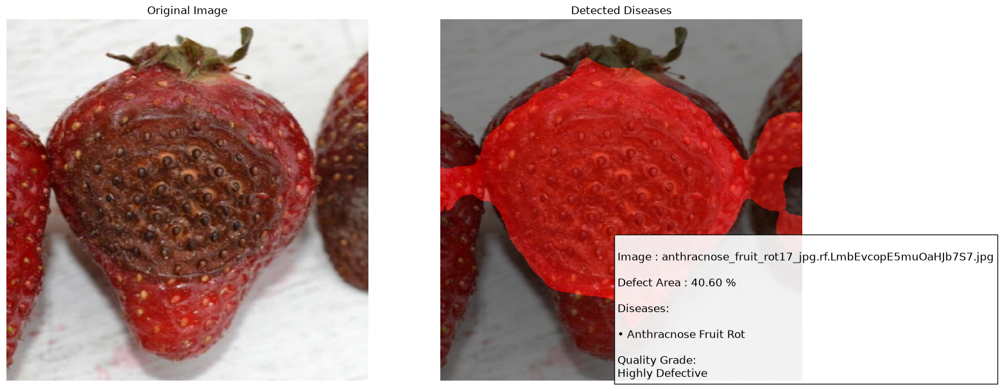

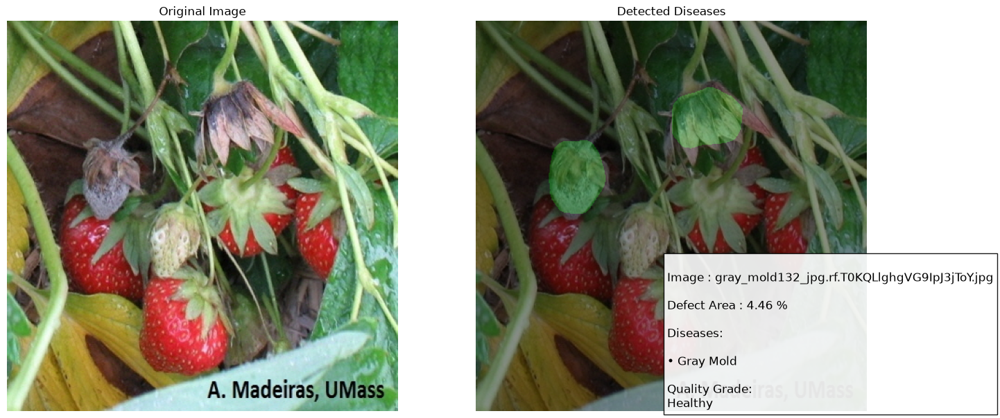

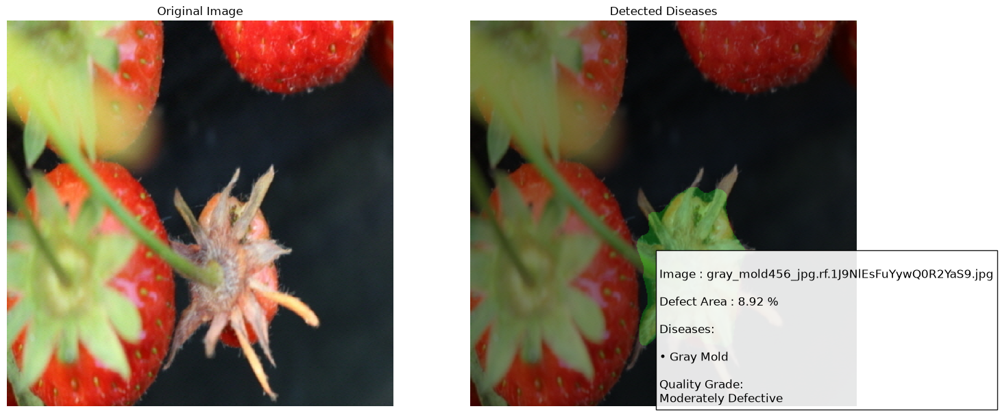

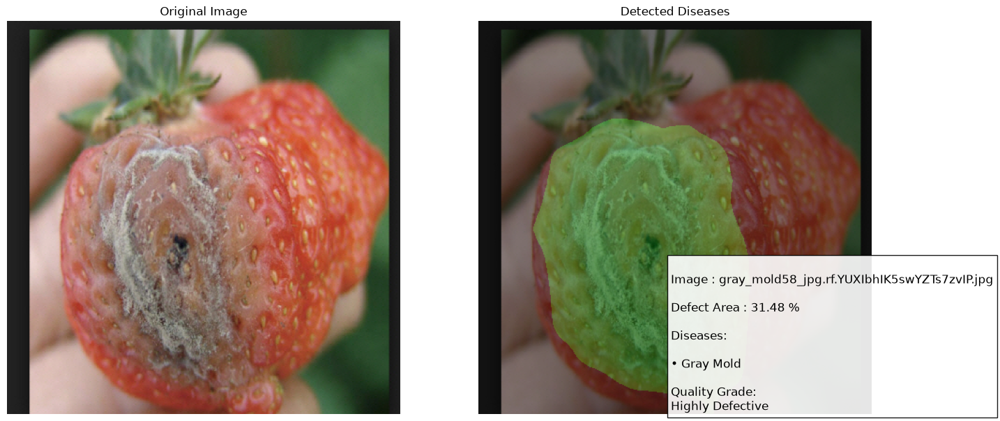

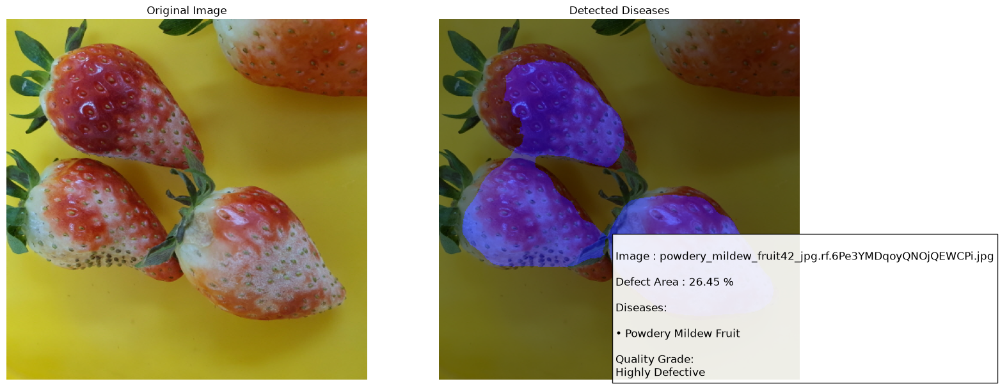

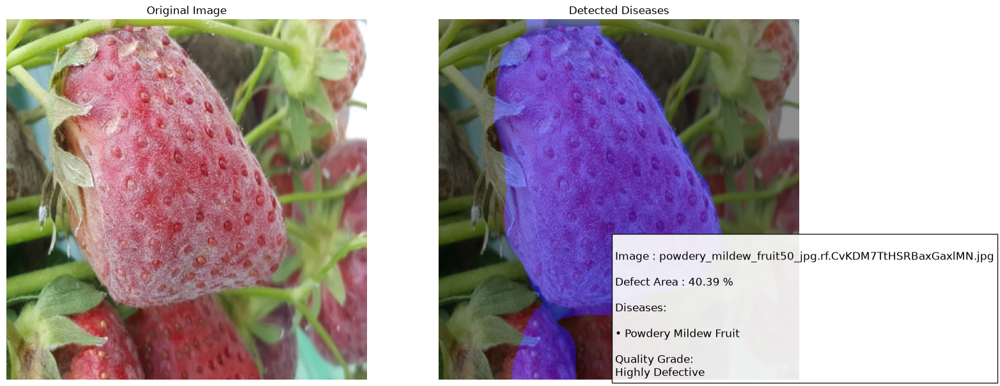

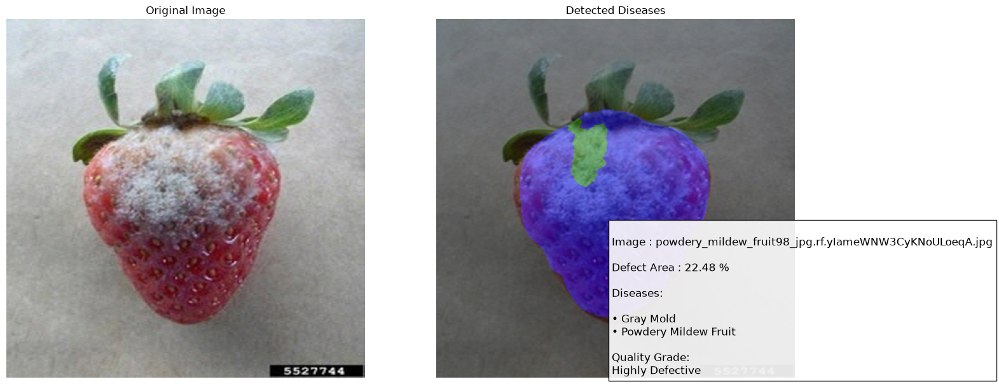

In [36]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "black",
    "red",
    "green",
    "blue"
])

for sample in results:

    fig = plt.figure(figsize=(16,8))

    plt.subplot(1,2,1)
    plt.imshow(sample["image"])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(sample["image"])
    plt.imshow(sample["prediction"], cmap=cmap, alpha=0.45, vmin=0, vmax=3)
    plt.title("Detected Diseases")
    plt.axis("off")

    text = f"""
Image : {sample['name']}

Defect Area : {sample['defect_percentage']:.2f} %

Diseases:
"""

    if len(sample["diseases"])==0:
        text += "\nHealthy"

    else:
        for d in sample["diseases"]:
            text += f"\n• {d}"

    if sample["defect_percentage"] < 5:
        grade = "Healthy"
    elif sample["defect_percentage"] < 20:
        grade = "Moderately Defective"
    else:
        grade = "Highly Defective"

    text += f"\n\nQuality Grade:\n{grade}"

    plt.figtext(
        0.72,
        0.15,
        text,
        fontsize=12,
        bbox=dict(facecolor="white", alpha=0.9)
    )

    plt.show()

In [37]:
def get_true_label(filename):

    filename = filename.lower()

    if "anthracnose" in filename:
        return 1

    elif "gray_mold" in filename:
        return 2

    elif "powdery_mildew" in filename:
        return 3

    else:
        return None

In [38]:
CLASS_NAMES = {
    1: "Anthracnose Fruit Rot",
    2: "Gray Mold",
    3: "Powdery Mildew"
}

In [39]:
import torch
import numpy as np
from PIL import Image

def predict_image(image_path):

    image = Image.open(image_path).convert("RGB")

    inputs = processor(images=image, return_tensors="pt")

    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)

    logits = outputs.logits

    predicted_mask = torch.nn.functional.interpolate(
        logits,
        size=image.size[::-1],
        mode="bilinear",
        align_corners=False
    )

    predicted_mask = predicted_mask.argmax(dim=1)[0].cpu().numpy()

    return predicted_mask

In [40]:
import numpy as np

def get_prediction(mask):

    labels, counts = np.unique(mask, return_counts=True)

    valid = labels != 0      # Ignore background

    labels = labels[valid]
    counts = counts[valid]

    if len(labels) == 0:
        return None

    return int(labels[np.argmax(counts)])

In [41]:
from sklearn.metrics import accuracy_score

y_true = []
y_pred = []

for image_name in os.listdir(UNSEEN_IMAGES_DIR):

    if not image_name.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    true_label = get_true_label(image_name)

    image_path = os.path.join(folder, image_name)

    result = predict_image(image_path)

    pred_label = get_prediction(result)

    if pred_label is None:
        continue

    y_true.append(true_label)
    y_pred.append(pred_label)

accuracy = accuracy_score(y_true, y_pred)

print(f"Accuracy : {accuracy*100:.2f}%")

Accuracy : 87.37%


In [42]:
correct = 0

for image_name in os.listdir(folder):

    if not image_name.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    true_label = get_true_label(image_name)

    result = predict_image(os.path.join(folder, image_name))

    pred_label = get_prediction(result)

    if pred_label is None:
        continue

    status = "✓" if true_label == pred_label else "✗"

    if status == "✓":
        correct += 1

    print(
        f"{status} {image_name:35s} "
        f"True: {CLASS_NAMES[true_label]:25s} "
        f"Pred: {CLASS_NAMES[pred_label]}"
    )

print(f"\nCorrect = {correct}/{len(y_true)}")

✓ powdery_mildew_fruit161.jpg         True: Powdery Mildew            Pred: Powdery Mildew
✓ powdery_mildew_leaf445.jpg          True: Powdery Mildew            Pred: Powdery Mildew
✗ powdery_mildew_leaf375.jpg          True: Powdery Mildew            Pred: Anthracnose Fruit Rot
✗ powdery_mildew_leaf533.jpg          True: Powdery Mildew            Pred: Gray Mold
✓ powdery_mildew_leaf428.jpg          True: Powdery Mildew            Pred: Powdery Mildew
✓ anthracnose_fruit_rot92.jpg         True: Anthracnose Fruit Rot     Pred: Anthracnose Fruit Rot
✓ gray_mold527.jpg                    True: Gray Mold                 Pred: Gray Mold
✗ powdery_mildew_leaf430.jpg          True: Powdery Mildew            Pred: Gray Mold
✓ gray_mold456.jpg                    True: Gray Mold                 Pred: Gray Mold
✗ powdery_mildew_leaf398.jpg          True: Powdery Mildew            Pred: Gray Mold
✓ gray_mold483.jpg                    True: Gray Mold                 Pred: Gray Mold
✓ gray_mold457.

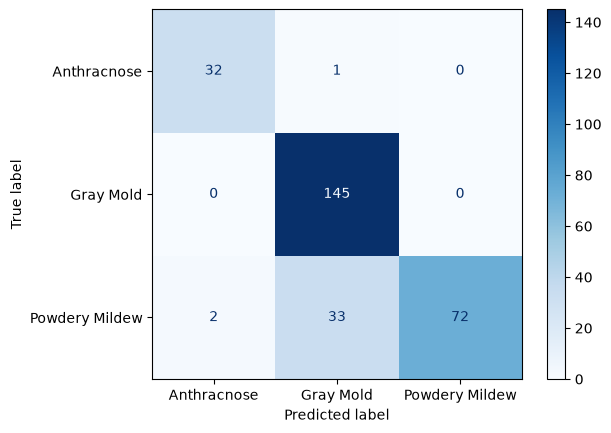

In [43]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Anthracnose",
        "Gray Mold",
        "Powdery Mildew"
    ]
)

disp.plot(cmap="Blues")
plt.show()

In [44]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=[
        "Anthracnose",
        "Gray Mold",
        "Powdery Mildew"
    ]
))

                precision    recall  f1-score   support

   Anthracnose       0.94      0.97      0.96        33
     Gray Mold       0.81      1.00      0.90       145
Powdery Mildew       1.00      0.67      0.80       107

      accuracy                           0.87       285
     macro avg       0.92      0.88      0.88       285
  weighted avg       0.90      0.87      0.87       285



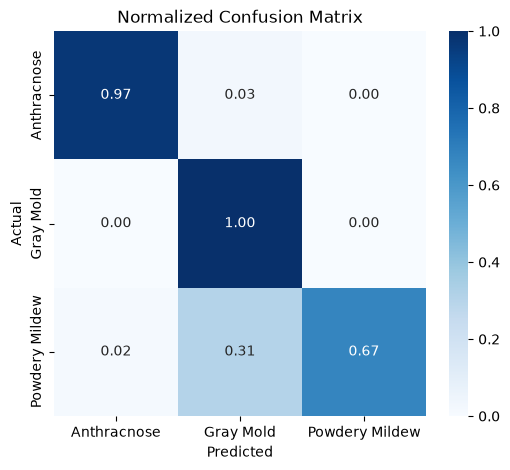

In [45]:
!pip install seaborn

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred,
    normalize='true'
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    cmap='Blues',
    fmt=".2f",
    xticklabels=[
        'Anthracnose',
        'Gray Mold',
        'Powdery Mildew'
    ],
    yticklabels=[
        'Anthracnose',
        'Gray Mold',
        'Powdery Mildew'
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Normalized Confusion Matrix")

plt.show()

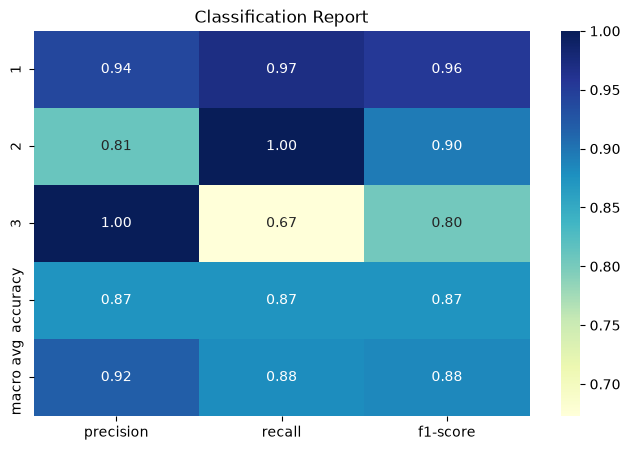

In [46]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_true,
    y_pred,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

plt.figure(figsize=(8,5))

sns.heatmap(
    report_df.iloc[:-1, :-1],
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Classification Report")

plt.show()